# TISI Mouse Xenium - Plotting

In [1]:
import spatialdata as sd
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm

In [2]:
# Settings
sc.settings.verbosity = 3
%matplotlib inline
sc.set_figure_params(figsize=(6, 6), frameon=False)

In [3]:
# Load pre-processed data
sdata = sd.read_zarr("TISI_mouse_xenium_5k_filtered_cropped.zarr")
adata = sc.read_h5ad("TISI_mouse_xenium_5k_annotated_cropped.h5ad")

g:\miniconda3\envs\xenium-io\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
no parent found for <ome_zarr.reader.Label object at 0x0000015A899BFF50>: None
no parent found for <ome_zarr.reader.Label object at 0x0000015A89CCFC20>: None
no parent found for <ome_zarr.reader.Label object at 0x0000015A89CDAFC0>: None
no parent found for <ome_zarr.reader.Label object at 0x0000015A89D140B0>: None
no parent found for <ome_zarr.reader.Label object at 0x0000015A89D14650>: None
no parent found for <ome_zarr.reader.Label object at 0x0000015A89C95910>: None


## Plot 1: TISI tumor cells boundaries (black background, cropped)

In [4]:
# ---------------------------------------------------------------
# Settings
# ---------------------------------------------------------------
crops = {
    "Control": (2000, 3000, 3500, 4500),
    "AC-d19": (3000, 4000, 3000, 4000),
    "AC+DCF-d19": (3500, 4500, 1000, 2000)
}

order = ["Epi-TISIlo", "Epi-TISImed", "Epi-TISIhi"]
tisi_colors = {
    "Epi-TISIlo":  "#4682B4",
    "Epi-TISImed": "#FFD700",
    "Epi-TISIhi":  "#E31A1C",
}

other_cell_color = "#AAAAAA"
edge_kw = dict(edgecolor="black", linewidth=0.1)
out_file = "figures/TISI_tumor_cells_boundaries_black_bg_cropped.pdf"

# Scale bar settings (in microns, since coordinates are in µm)
scale_bar_length = 200   # length of scale bar in microns
scale_bar_y_offset = 30  # vertical offset from bottom edge (data coords)
scale_bar_linewidth = 2.0

In [5]:
# ---------------------------------------------------------------
# Map each sample to its cell_boundaries element in sdata
# ---------------------------------------------------------------
sample_to_shapes = (
    adata.obs.groupby("sample", observed=True)["region"].first()
.astype(str)
.str.replace("cell_labels-", "cell_boundaries-", n=1)
.to_dict()
)

def get_boundaries(sdata, sample):
    return sdata.shapes[sample_to_shapes[sample]]

In [6]:
adata.obs['sample'].value_counts()

sample
Control       8402
AC+DCF-d19    5719
AC-d19        4304
Name: count, dtype: int64


Control: 8402 tumor cells matched to boundaries
  - Other cell types: 2878
  - Epi-TISIlo: 647
  - Epi-TISImed: 3501
  - Epi-TISIhi: 1376

AC-d19: 4304 tumor cells matched to boundaries
  - Other cell types: 665
  - Epi-TISIlo: 548
  - Epi-TISImed: 1490
  - Epi-TISIhi: 1601

AC+DCF-d19: 5719 tumor cells matched to boundaries
  - Other cell types: 3444
  - Epi-TISIlo: 983
  - Epi-TISImed: 811
  - Epi-TISIhi: 481


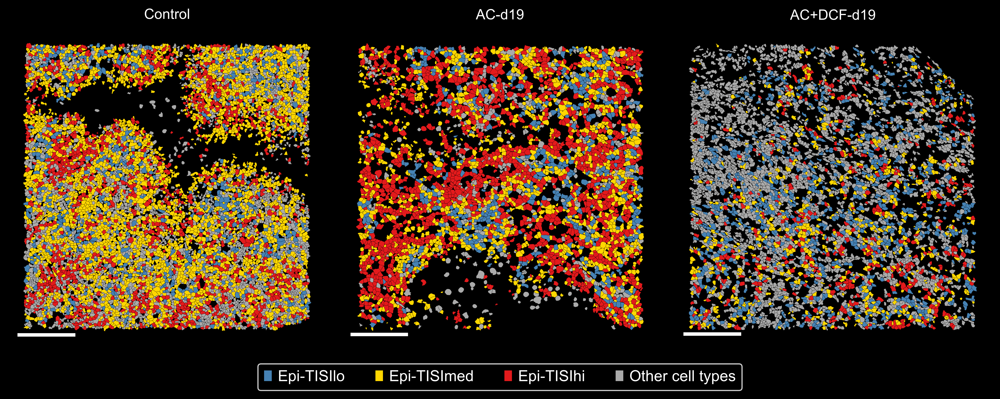

In [7]:
# ---------------------------------------------------------------
# Plot
# ---------------------------------------------------------------
samples = ['Control', 'AC-d19', 'AC+DCF-d19']

fig, axes = plt.subplots(1, len(samples), figsize=(4 * len(samples), 5), dpi=300, facecolor="black")
axes = np.atleast_1d(axes)

has_other_cells = False

for ax, s in zip(axes, samples):
    gdf = get_boundaries(sdata, s)

    all_ann = adata.obs.loc[adata.obs["sample"] == s].set_index("cell_id")
    cells = gdf.join(all_ann["TISI_ann"], how="inner", rsuffix="_ann")
    print(f"\n{s}: {len(cells)} tumor cells matched to boundaries")

    other_cells = cells[~cells["TISI_ann"].isin(order)]
    print(f"  - Other cell types: {len(other_cells)}")
    if len(other_cells):
        has_other_cells = True
        other_cells.plot(ax=ax, color=other_cell_color, **edge_kw)

    for cat in order:
        sub = cells[cells["TISI_ann"] == cat]
        print(f"  - {cat}: {len(sub)}")
        if len(sub):
            sub.plot(ax=ax, color=tisi_colors[cat], **edge_kw)

    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_facecolor("black")
    ax.set_axis_off()
    ax.set_title(s, color="white", fontsize=12, pad=8)

    # ---------------------------------------------------------------
    # Scale bar (bottom-left), independent of axis inversion
    # ---------------------------------------------------------------
    scalebar = AnchoredSizeBar(
        ax.transData,
        scale_bar_length,           
        "",
        loc="lower left",
        pad=0.4,
        borderpad=0.5,
        sep=4,                         
        color="white",
        frameon=False,
        size_vertical=scale_bar_linewidth * 4, 
        label_top=True,                
        fontproperties=fm.FontProperties(size=9),
    )
    ax.add_artist(scalebar)

# Symmetric margins first
fig.subplots_adjust(left=0.02, right=0.98, wspace=0.05, bottom=0.12)

# Draw once so aspect-adjusted axes positions are final
fig.canvas.draw()
# With this:
bbox_left = axes[0].get_position()
bbox_right = axes[-1].get_position()
x_left = bbox_left.x0
x_right = bbox_right.x1
x_center = (x_left + x_right) / 2

# Legend
handles = [Patch(facecolor=tisi_colors[c], edgecolor="none", label=c) for c in order]
if has_other_cells:
    handles.append(Patch(facecolor=other_cell_color, edgecolor="none", label="Other cell types"))

fig.legend(handles=handles, loc="lower center", ncol=len(handles),
           bbox_to_anchor=(x_center, 0.02), bbox_transform=fig.transFigure,
           frameon=True, facecolor="black", edgecolor="white", labelcolor="white")

fig.savefig(out_file, dpi=300, bbox_inches="tight",
            facecolor=fig.get_facecolor(), edgecolor="none")
plt.show()

## Plot 2: TISI annotation proportions bar graph

In [8]:
# Define colors for all TISI annotations
tisi_colors = {
    'Epi-TISIlo': '#4682B4',   
    'Epi-TISImed': '#FFD700',  
    'Epi-TISIhi': '#E31A1C',    
    'Macrophage': '#A65628',
    'Monocyte': '#F781BF',
    "NK/T": '#999999',
    "Vascular": '#66C2A5',  
    "CAF": '#FC8D62',
    "Low-quality": '#8DA0CB',
    "Neutrophil": '#E78AC3',
    "Giant cell": '#A6D854',
}

# Set colors in adata.uns for plotting
adata.uns['TISI_ann_colors'] = [tisi_colors[cat] for cat in adata.obs['TISI_ann'].cat.categories]

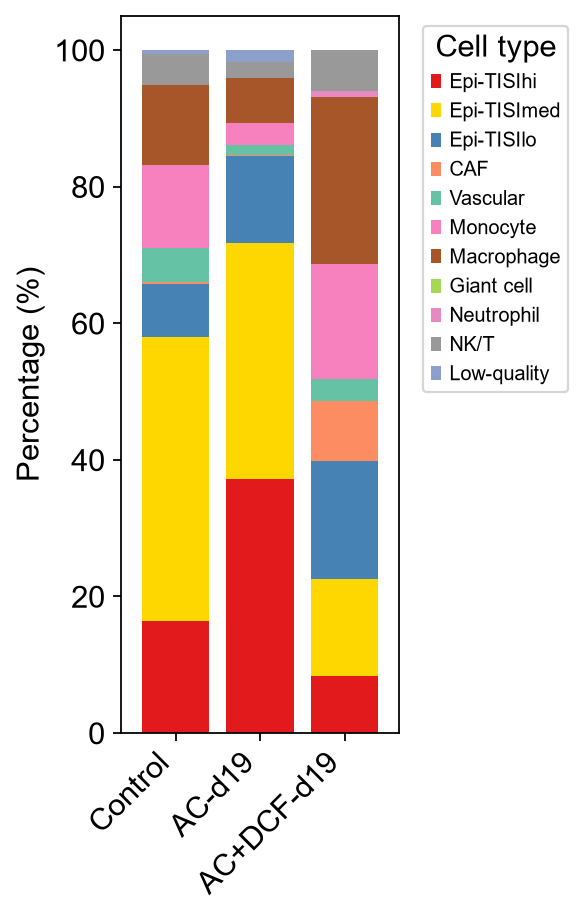

In [9]:
# Create cross-tabulation of samples vs TISI annotations
table = pd.crosstab(adata.obs["sample"], adata.obs["TISI_ann"])
prop_table = table.div(table.sum(axis=1), axis=0) * 100

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(4, 6))
prop_table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=adata.uns['TISI_ann_colors'],
    width=0.8,
)

ax.set_ylabel("Percentage (%)")
ax.set_xlabel("")
ax.grid(False)
ax.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig('figures/bargraph_TISI_ann_proportions.pdf')
plt.show()

C:\Users\winst\AppData\Local\Temp\ipykernel_29148\2519375337.py:9: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata_epi.uns['TISI_ann_colors'] = [epi_tisi_colors[cat] for cat in adata_epi.obs['TISI_ann'].cat.categories]


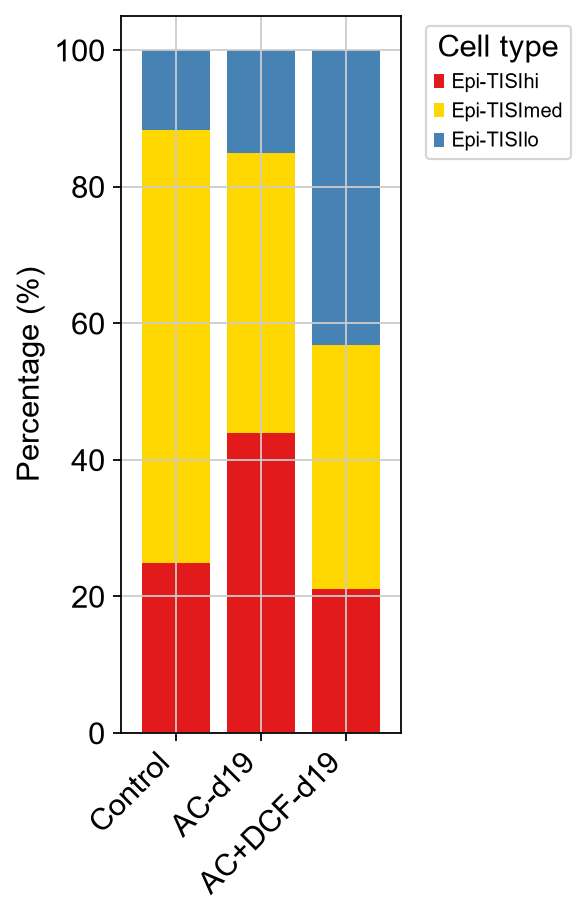

In [10]:
# EPI-only: Create cross-tabulation of samples vs TISI annotations
adata_epi = adata[adata.obs['TISI_ann'].isin(['Epi-TISIhi', 'Epi-TISImed', 'Epi-TISIlo'])]

epi_tisi_colors = {
    'Epi-TISIlo': '#4682B4',   # SteelBlue
    'Epi-TISImed': '#FFD700',  # Gold
    'Epi-TISIhi': '#E31A1C',    # Red
}
adata_epi.uns['TISI_ann_colors'] = [epi_tisi_colors[cat] for cat in adata_epi.obs['TISI_ann'].cat.categories]

table = pd.crosstab(adata_epi.obs["sample"], adata.obs["TISI_ann"])
# table = table.loc[:, table.columns.isin(["Epi-TISIhi", "Epi-TISImed", "Epi-TISIlo"])]
prop_table = table.div(table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(4, 6))
prop_table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=adata_epi.uns['TISI_ann_colors'],
    width=0.8,
)

ax.set_ylabel("Percentage (%)")
ax.set_xlabel("")
ax.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig('figures/bargraph_TISI_ann_proportions_epi_only.pdf')
plt.show()

In [11]:
import session_info2
session_info2.session_info()

C:\Users\winst\AppData\Local\Temp\ipykernel_29148\669142187.py:2: RuntimeWarning: Failed to import dependencies for application/vnd.jupyter.widget-view+json representation. (ModuleNotFoundError: No module named 'ipywidgets')
  session_info2.session_info()


Package,Version
pandas,2.3.3
spatialdata,0.8.0
scanpy,1.11.5
numpy,2.0.1
matplotlib,3.11.2
anndata,0.12.19
geopandas,1.1.4
Component,Info
Python,"3.12.14 | packaged by conda-forge | (main, Sep 2 2026, 23:18:20) [MSC v.1944 64 bit (AMD64)]"
OS,Windows-11-10.0.26200-SP0
